# Vinculum 00 · Market cap, size universes and fundamentals per security

`vinculum` joins Massive (prices, the security master) with SEC EDGAR (share counts,
fundamentals). The join is where silent errors live: a wrong CIK attaches another company's
numbers, and splits, ADR ratios, share classes and unit errors in filings make share counts
disagree with the traded security by factors of 2 to 1,000,000. This notebook shows what the
built tables contain and how each of those problems is handled.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl
from massive_subspace_stream import Store
from subspace_probe import style, timed
from vinculum import SIZE_BUCKETS, Vinculum

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_fmt_str_lengths(40)
v = Vinculum()
massive = Store()


def trading_day(d: date) -> date:
    """Last trading day on or before d."""
    return v.scan().filter(pl.col("date") <= d).select(pl.col("date").max()).collect().item()


info = v.status()
print(f"built {info['built_at']} through {info['through']}: {info['rows']:,} rows, "
      f"{info['market_cap_bytes'] / 1e9:.2f} GB, {info['seconds']} s")

built 2026-11-01T19:01:06+00:00 through 2026-10-30: 31,068,107 rows, 0.71 GB, 26.5 s


## 1 · A checked CIK for every security

Massive's point-in-time reference records carry a CIK. Each run of the same CIK is checked
against the SEC's own name history (`EdgarStore.names()`): names must match, an unknown CIK
shared by unrelated stocks at the same time is rejected, and missing or wrong CIKs are repaired
by a unique name match among companies that filed reports in that period.

In [2]:
m = v.cik_map()
print(m.group_by("status").len().sort("len", descending=True))
examples = ["CIK:0000935113:TASR", "CIK:0000935113:QSII", "BBG000CPHYL4", "BBG000HYNQP6"]
m.filter(pl.col("security_id").is_in(examples)).select(
    "security_id", "valid_from", "massive_cik", "cik", "status", "massive_name", "edgar_name")

shape: (7, 2)
┌────────────┬───────┐
│ status     ┆ len   │
│ ---        ┆ ---   │
│ str        ┆ u32   │
╞════════════╪═══════╡
│ verified   ┆ 23623 │
│ unverified ┆ 8383  │
│ missing    ┆ 5827  │
│ filled     ┆ 2042  │
│ repaired   ┆ 1415  │
│ rejected   ┆ 960   │
│ ticker     ┆ 128   │
└────────────┴───────┘


security_id,valid_from,massive_cik,cik,status,massive_name,edgar_name
str,date,str,str,str,str,str
"""BBG000CPHYL4""",1900-01-01,"""0000880036""",null,"""rejected""","""TENET HEALTHCARE CORPORATION""","""HOCKEY CO"""
"""BBG000CPHYL4""",2012-10-31,"""0000070318""","""0000070318""","""verified""","""TENET HEALTHCARE CORPORATION""","""TENET HEALTHCARE CORP"""
"""BBG000HYNQP6""",1900-01-01,"""0000315858""","""0000867665""","""repaired""","""ABRAXAS PETROLEUM CORP.""","""Bluegreen Vacations Holding Corp"""
"""BBG000HYNQP6""",2020-10-30,"""0001006438""","""0001006438""","""unverified""","""Abraxas Petroleum Corporation""",null
"""CIK:0000935113:QSII""",1900-01-01,"""0000935113""","""0000708818""","""repaired""","""QUALITY SYS INC""",null
"""CIK:0000935113:TASR""",1900-01-01,"""0000935113""","""0001069183""","""repaired""","""TASER INTERNATIONAL INC""",null


CIK 0000935113 is not a company the SEC knows, yet Massive's old snapshots attach it to Taser,
Quality Systems, Dawson Geophysical and others; they are repaired by name. Tenet Healthcare's
old CIK points to "Hockey Co" and Abraxas Petroleum's to a vacation company: those mismatches
are rejected (or repaired when the right company can be found).

coverage by year: 0.16 s


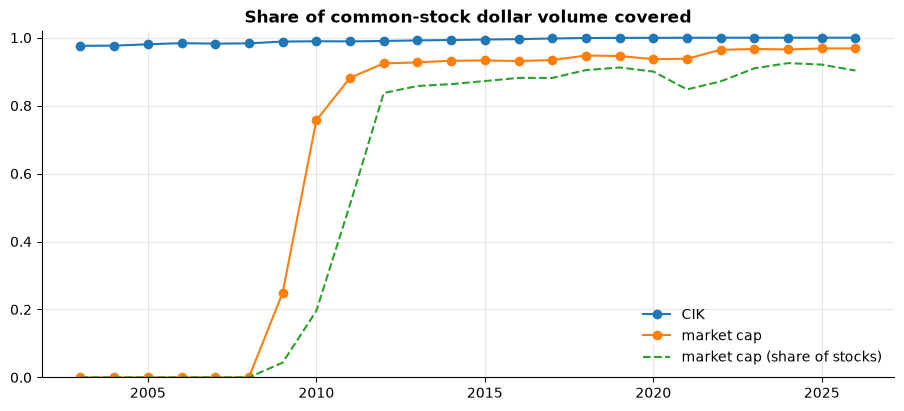

In [3]:
yr = pl.col("date").dt.year().alias("year")
with timed("coverage by year"):
    cov = (v.scan().filter(pl.col("type") == "CS").group_by(yr)
           .agg(((pl.col("cik").is_not_null().cast(pl.Float64) * pl.col("dollar_volume")).sum()
                 / pl.col("dollar_volume").sum()).alias("cik"),
                ((pl.col("market_cap").is_not_null().cast(pl.Float64) * pl.col("dollar_volume")).sum()
                 / pl.col("dollar_volume").sum()).alias("market_cap"),
                pl.col("market_cap").is_not_null().mean().alias("rows_with_cap"))
           .collect().sort("year"))
fig, ax = plt.subplots()
ax.plot(cov["year"], cov["cik"], marker="o", label="CIK")
ax.plot(cov["year"], cov["market_cap"], marker="o", label="market cap")
ax.plot(cov["year"], cov["rows_with_cap"], ls="--", label="market cap (share of stocks)")
ax.set_ylim(0, 1.02)
ax.set_title("Share of common-stock dollar volume covered")
ax.legend()
plt.show()

Market cap starts with XBRL (2009 for large filers, 2011 for all) and covers 92-96% of
common-stock dollar volume since 2012. The stocks without one are mostly tiny, recent
listings or foreign filers before their first XBRL report.

## 2 · Share counts in the security's own units

The SEC reports counts as filed. vinculum puts every count in *today's* units of the security
(`shares_now`), so market cap = split-adjusted close × shares_now × basis ratio.

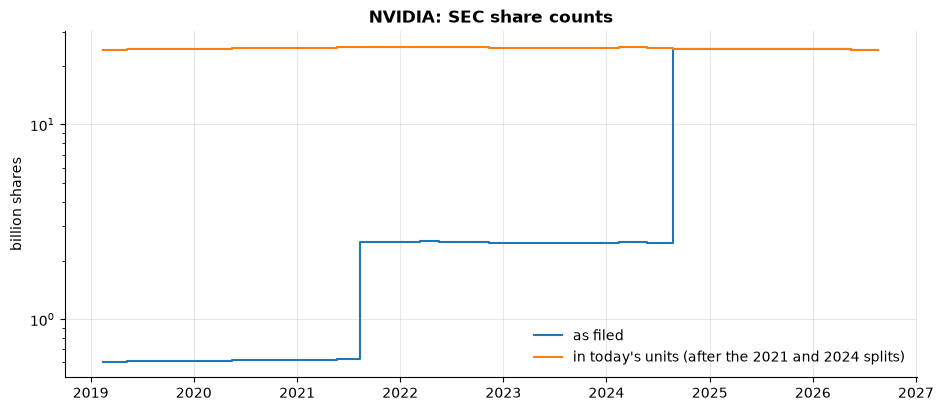

In [4]:
nvda = massive.resolve(["NVDA"]).row(0, named=True)["security_id"]
c = v.share_counts(nvda).filter(pl.col("end") >= date(2019, 1, 1)).sort("end")
fig, ax = plt.subplots()
ax.step(c["end"], c["shares"] / 1e9, where="post", label="as filed")
ax.step(c["end"], c["shares_now"] / 1e9, where="post", label="in today's units (after the 2021 and 2024 splits)")
ax.set_yscale("log")
ax.set_ylabel("billion shares")
ax.set_title("NVIDIA: SEC share counts")
ax.legend()
plt.show()

Unit errors are common: companies report counts in thousands (or millions) for a while. Steps
of exactly 1000ⁿ and the implied turnover (dollar volume / market cap) find them; each level is
moved to where turnover is plausible. ON Semiconductor reported 455 *trillion* shares for two
quarters of 2012:

In [5]:
on = v.share_counts().filter(pl.col("cik") == "0001097864").filter(pl.col("end").dt.year() == 2012)
on.select("end", "filed", "shares", "shares_now", "unit_fixed", "tag")

end,filed,shares,shares_now,unit_fixed,tag
date,date,f64,f64,bool,str
2012-02-17,2012-02-22,4.52136921e8,4.52136921e8,false,"""dei:EntityCommonStockSharesOutstanding"""
2012-04-26,2012-05-04,4.54082151e8,4.54082151e8,false,"""dei:EntityCommonStockSharesOutstanding"""
2012-07-26,2012-08-03,4.5557e14,4.55571966e8,true,"""dei:EntityCommonStockSharesOutstanding"""
2012-10-26,2012-11-02,4.4829e14,4.48293513e8,true,"""dei:EntityCommonStockSharesOutstanding"""


In [6]:
print(f"counts: {info['share_counts']:,}   unit levels fixed: {info['unit_fixed']:,}   "
      f"lasting unexplained jumps: {info['share_jumps']:,}   splits not applied (ADR ratio, class units): "
      f"{info['splits_not_applied']}")

counts: 373,237   unit levels fixed: 3,635   lasting unexplained jumps: 5,697   splits not applied (ADR ratio, class units): 144


## 3 · Basis ratios: ADRs and share classes

The SEC counts ordinary shares; the price is per ADS. Berkshire reports Class A equivalents;
BRK.B is 1/1500 of an A share. The ratio (traded units per SEC unit) comes from Massive's
current share count, snapped to round numbers.

In [7]:
ids = massive.resolve(["TSM", "BABA", "BRK.B", "BRK.A", "GOOG", "GOOGL", "AAPL"], on="2026-10-30")
v.basis(ids["security_id"].to_list()).join(ids.select("security_id", "ticker"), on="security_id").select(
    "ticker", "type", "massive_shares", "sec_shares", "basis_ratio", "basis")

ticker,type,massive_shares,sec_shares,basis_ratio,basis
str,str,f64,f64,f64,str
"""TSM""","""ADRC""",5.1865e9,2.5933e10,0.2,"""calibrated"""
"""BABA""","""ADRC""",2.4877e9,1.8580e10,0.125,"""calibrated"""
"""BRK.B""","""CS""",2.1407e9,null,1500.0,"""override"""
"""BRK.A""","""CS""",1.42714e6,null,1.0,"""assumed"""
"""GOOG""","""CS""",1.2294e10,1.2294e10,1.0,"""calibrated"""
"""GOOGL""","""CS""",1.2294e10,1.2294e10,1.0,"""calibrated"""
"""AAPL""","""CS""",1.4594e10,1.4609e10,1.0,"""calibrated"""


In [8]:
print(v.basis().group_by("type", "basis").len().sort("type", "len", descending=[False, True]))

shape: (10, 3)
┌──────┬────────────────┬──────┐
│ type ┆ basis          ┆ len  │
│ ---  ┆ ---            ┆ ---  │
│ str  ┆ str            ┆ u32  │
╞══════╪════════════════╪══════╡
│ null ┆ assumed        ┆ 7146 │
│ ADRC ┆ unknown        ┆ 387  │
│ ADRC ┆ calibrated     ┆ 277  │
│ ADRC ┆ calibrated_raw ┆ 6    │
│ CS   ┆ assumed        ┆ 7248 │
│ CS   ┆ calibrated     ┆ 4104 │
│ CS   ┆ loose          ┆ 272  │
│ CS   ┆ disagree       ┆ 236  │
│ CS   ┆ rescaled       ┆ 7    │
│ CS   ┆ override       ┆ 1    │
└──────┴────────────────┴──────┘


`assumed` are mostly delisted stocks (no current Massive count; ratio 1). `loose` and
`disagree` keep ratio 1: for a single-class stock the SEC count is the company's, and a
disagreement with Massive (Up-C structures, timing) never rescales a whole history.

## 4 · Market cap

Point in time: each day uses the latest SEC count usable that day (the day after filing).

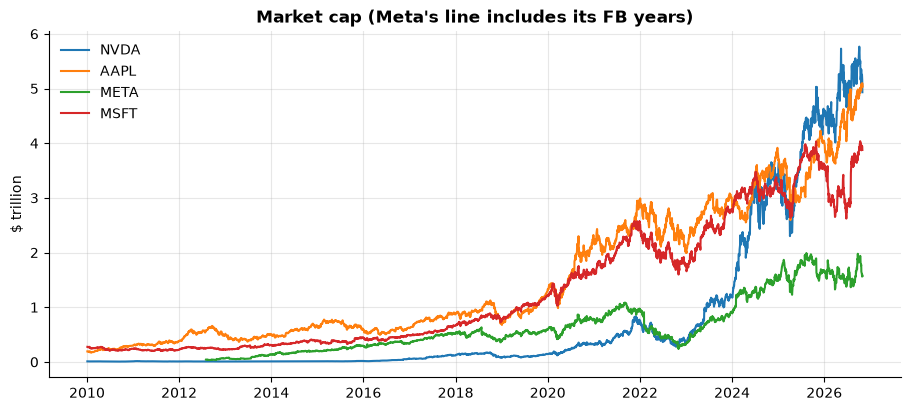

In [9]:
mc = v.market_cap(["AAPL", "MSFT", "NVDA", "META"], start="2010-01-01", by="security", primary_only=True)
fig, ax = plt.subplots()
for _, g in mc.group_by("security_id"):
    ax.plot(g["date"], g["market_cap"] / 1e12, label=g["ticker"][-1])
ax.set_ylabel("$ trillion")
ax.set_title("Market cap (Meta's line includes its FB years)")
ax.legend()
plt.show()

Multi-class companies count once: each class carries the company's value seen through its own
price (`market_cap`), and the most traded class is `is_primary` with `issuer_market_cap`.

In [10]:
v.market_cap(["GOOG", "GOOGL", "BRK.A", "BRK.B"], start="2014-12-31", end="2014-12-31").select(
    "ticker", "close", "shares", "basis_ratio", "market_cap", "issuer_market_cap", "is_primary")

ticker,close,shares,basis_ratio,market_cap,issuer_market_cap,is_primary
str,f64,f64,f64,f64,f64,bool
"""BRK.A""",226000.0,1.642558e6,1.0,3.7122e11,3.6995e11,false
"""BRK.B""",150.15,2.4638e9,1500.0,3.6995e11,3.6995e11,true
"""GOOGL""",530.66,6.7710e8,1.0,3.5931e11,3.5931e11,true
"""GOOG""",526.4,6.7710e8,1.0,3.5642e11,3.5931e11,false


Against Massive's own current market caps (its `ticker_details` snapshot):

shape: (5, 3)
┌────────────────┬──────┬──────────────┐
│ basis          ┆ len  ┆ within_10pct │
│ ---            ┆ ---  ┆ ---          │
│ str            ┆ u32  ┆ f64          │
╞════════════════╪══════╪══════════════╡
│ calibrated     ┆ 4377 ┆ 0.984236     │
│ loose          ┆ 271  ┆ 0.01107      │
│ disagree       ┆ 195  ┆ 0.010256     │
│ calibrated_raw ┆ 6    ┆ 1.0          │
│ rescaled       ┆ 5    ┆ 1.0          │
└────────────────┴──────┴──────────────┘


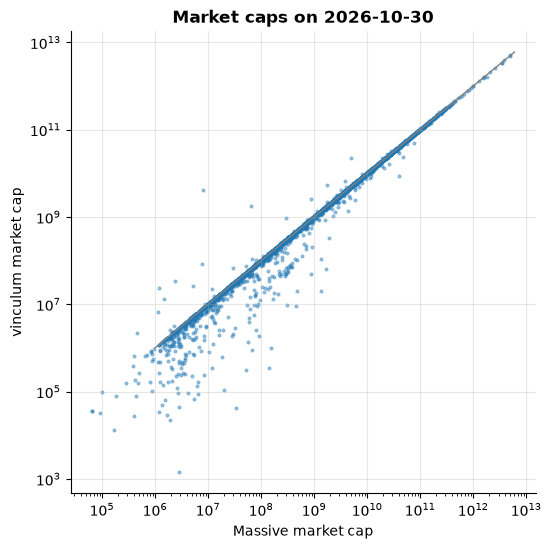

In [11]:
last = info["through"]
b = v.basis().filter(pl.col("massive_market_cap").is_not_null())
today = v.market_cap(start=last, end=last).select("security_id", "ticker", "market_cap")
j = b.join(today, on="security_id").filter(pl.col("market_cap").is_not_null()).with_columns(
    (pl.col("market_cap") / pl.col("massive_market_cap")).alias("ratio"))
print(j.group_by("basis").agg(pl.len(), ((pl.col("ratio") - 1).abs() < 0.1).mean().alias("within_10pct"))
      .sort("len", descending=True))
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(j["massive_market_cap"], j["market_cap"], s=4, alpha=0.4)
ax.set_xscale("log")
ax.set_yscale("log")
ax.plot([1e6, 6e12], [1e6, 6e12], color="grey", lw=1)
ax.set_xlabel("Massive market cap")
ax.set_ylabel("vinculum market cap")
ax.set_title(f"Market caps on {last}")
plt.show()

## 5 · Size universes

Companies are ranked by `issuer_market_cap` at the previous month end (like an index
reconstitution) and bucketed Russell-style:

In [12]:
print(SIZE_BUCKETS)
counts = []
for y in range(2011, 2027):
    u = v.universe(trading_day(date(y, 6, 15)))
    counts.append(u.group_by("size").len().with_columns(pl.lit(y).alias("year")))
sizes = pl.concat(counts).pivot(on="size", index="year", values="len").sort("year")
sizes

{'large': (1, 200), 'mid': (201, 1000), 'small': (1001, 3000), 'micro': (3001, None)}


year,large,mid,small,micro
i32,u32,u32,u32,u32
2011,200,797,327,null
2012,200,800,1987,268
2013,199,799,1993,401
2014,200,800,1996,601
2015,200,799,1999,811
2016,199,799,1995,902
2017,200,797,1992,939
2018,198,797,1990,1147
2019,199,799,1992,1164


In [13]:
tops = {y: v.ranks(trading_day(date(y, 12, 31))).head(5)["ticker"].to_list() for y in range(2010, 2027, 2)}
pl.DataFrame({"year": list(tops), "top 5": [", ".join(t) for t in tops.values()]})

year,top 5
i64,str
2010,"""XOM, AAPL, MSFT, BRK.B, GE"""
2012,"""AAPL, XOM, GOOG, WMT, MSFT"""
2014,"""AAPL, XOM, MSFT, BRK.B, GOOGL"""
2016,"""AAPL, GOOGL, MSFT, XOM, AMZN"""
2018,"""MSFT, AAPL, AMZN, GOOGL, FB"""
2020,"""AAPL, MSFT, AMZN, GOOGL, FB"""
2022,"""AAPL, MSFT, GOOGL, AMZN, UNH"""
2024,"""AAPL, NVDA, MSFT, GOOGL, AMZN"""
2026,"""AAPL, NVDA, MSFT, GOOGL, AMZN"""


Universes are survivorship free: companies are chosen on the rank date whatever happened
later. Of the 2015 small-cap universe, this many stocks no longer trade:

In [14]:
u = v.universe("2015-06-15", size="small")
secs = massive.securities().select("security_id", "last_trade")
gone = u.join(secs, on="security_id").filter(pl.col("last_trade") < date(2026, 1, 1))
print(f"{gone.height:,} of {u.height:,} ({gone.height / u.height:.0%}) later delisted, merged or renamed into a new security")

1,002 of 1,999 (50%) later delisted, merged or renamed into a new security


## 6 · Point-in-time fundamentals per security

Trailing-twelve-month flows (usable once the last quarter was filed), latest balance sheet,
stale after 400 days, and valuation ratios over issuer market cap for USD reporters (BABA
reports in its own currency: values, but no ratios).

In [15]:
with timed("fundamentals, month ends 2012-2026"):
    f = v.fundamentals(["revenue", "net_income", "equity"], start="2012-01-01")
f.filter(pl.col("ticker").is_in(["AAPL", "JPM", "BABA"]) & (pl.col("date") == pl.col("date").max())).select(
    "date", "ticker", "issuer_market_cap", "revenue", "net_income", "equity", "currency",
    "earnings_yield", "book_to_market")

fundamentals, month ends 2012-2026: 5.73 s


date,ticker,issuer_market_cap,revenue,net_income,equity,currency,earnings_yield,book_to_market
date,str,f64,f64,f64,f64,str,f64,f64
2026-10-30,"""AAPL""",5.0347e12,4.6682e11,1.2893e11,1.0752e11,"""USD""",0.025608,0.021356
2026-10-30,"""JPM""",8.9592e11,1.9941e11,6.5067e10,3.7460e11,"""USD""",0.072626,0.418118
2026-10-30,"""BABA""",2.2770e11,1.0237e12,1.5018e10,1.5380e11,"""CNY""",null,null


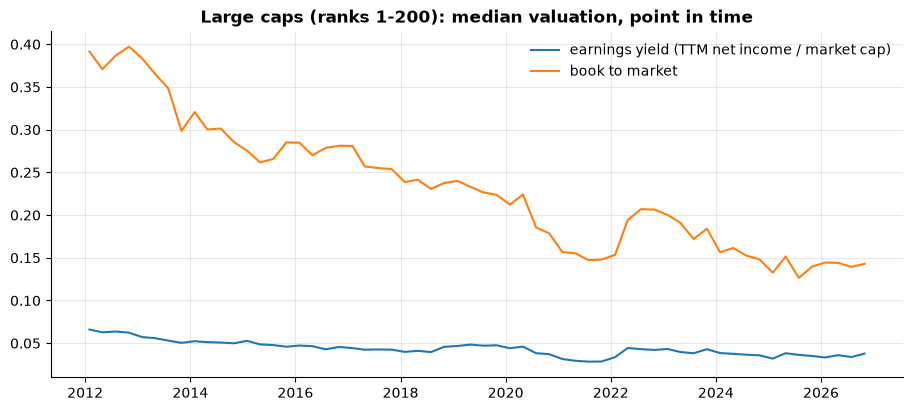

In [16]:
large = f.join(pl.concat([v.universe(d, size="large").select("security_id", pl.lit(d).alias("date"))
                          for d in sorted(f["date"].unique().to_list())[::3]]), on=["security_id", "date"])
med = large.group_by("date").agg(pl.col("earnings_yield").median(), pl.col("book_to_market").median()).sort("date")
fig, ax = plt.subplots()
ax.plot(med["date"], med["earnings_yield"], label="earnings yield (TTM net income / market cap)")
ax.plot(med["date"], med["book_to_market"], label="book to market")
ax.set_title("Large caps (ranks 1-200): median valuation, point in time")
ax.legend()
plt.show()

## 7 · Limits

- No market cap before XBRL (2009 large filers, 2011 small; foreign filers about 2017-18).
- ADR and class ratios come from today's Massive counts, so delisted ADRs have no market cap.
- Multi-class companies lose market cap where the SEC has no company-wide count (Berkshire
  after 2016); tracking stocks get none.
- Ratios only for USD reporters (no FX conversion).

More in this folder: `01_fundamentals` (every field, coverage, pitfalls), `02_ratios` (a ratio library, sectors, history), `03_factor_sorts` (point-in-time quintile sorts) `04_float_and_short` (public float, short interest) and `05_signals` (the neural-processor signal library).